In [3]:

import os
import random
import hashlib
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from IPython.display import display

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

print("Libraries imported successfully!")


Libraries imported successfully!


In [4]:

%cd /kaggle/working

REPO_DIR = "/kaggle/working/PlantVillage-Dataset"

if not os.path.exists(REPO_DIR):
    !git clone --depth 1 --filter=blob:none --sparse https://github.com/spMohanty/PlantVillage-Dataset

%cd /kaggle/working/PlantVillage-Dataset
!git sparse-checkout set raw/color

%cd /kaggle/working

DATA_DIR = os.path.join(REPO_DIR, "raw", "color")

print("Dataset exists:", os.path.exists(DATA_DIR))


/kaggle/working
Cloning into 'PlantVillage-Dataset'...
remote: Enumerating objects: 206, done.
remote: Counting objects: 100% (206/206), done.
remote: Compressing objects: 100% (169/169), done.
remote: Total 206 (delta 37), reused 204 (delta 37), pack-reused 0 (from 0)
Receiving objects: 100% (206/206), 7.47 MiB | 31.63 MiB/s, done.
Resolving deltas: 100% (37/37), done.
remote: Enumerating objects: 9, done.
remote: Counting objects: 100% (9/9), done.
remote: Compressing objects: 100% (9/9), done.
remote: Total 9 (delta 0), reused 7 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (9/9), 255.05 KiB | 5.54 MiB/s, done.
/kaggle/working/PlantVillage-Dataset
remote: Enumerating objects: 54284, done.
remote: Counting objects: 100% (54284/54284), done.
remote: Compressing objects: 100% (54284/54284), done.
remote: Total 54284 (delta 0), reused 54284 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (54284/54284), 801.17 MiB | 16.06 MiB/s, done.
Updating files: 100% (54305/543

In [7]:

classes = sorted([
    c for c in os.listdir(DATA_DIR)
    if os.path.isdir(os.path.join(DATA_DIR, c))
])

print("Total classes:", len(classes))

for c in classes:
    print(c)


Total classes: 38
Apple___Apple_scab
Apple___Black_rot
Apple___Cedar_apple_rust
Apple___healthy
Blueberry___healthy
Cherry_(including_sour)___Powdery_mildew
Cherry_(including_sour)___healthy
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Corn_(maize)___Common_rust_
Corn_(maize)___Northern_Leaf_Blight
Corn_(maize)___healthy
Grape___Black_rot
Grape___Esca_(Black_Measles)
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
Grape___healthy
Orange___Haunglongbing_(Citrus_greening)
Peach___Bacterial_spot
Peach___healthy
Pepper,_bell___Bacterial_spot
Pepper,_bell___healthy
Potato___Early_blight
Potato___Late_blight
Potato___healthy
Raspberry___healthy
Soybean___healthy
Squash___Powdery_mildew
Strawberry___Leaf_scorch
Strawberry___healthy
Tomato___Bacterial_spot
Tomato___Early_blight
Tomato___Late_blight
Tomato___Leaf_Mold
Tomato___Septoria_leaf_spot
Tomato___Spider_mites Two-spotted_spider_mite
Tomato___Target_Spot
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Tomato___Tomato_mosaic_virus
Tomato___health

In [8]:

class_counts = {}

for c in classes:
    folder = os.path.join(DATA_DIR, c)

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    class_counts[c] = len(images)

df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Images"]
)

df["Percentage"] = (
    df["Images"] / df["Images"].sum() * 100
).round(2)

print("Total classes:", len(classes))
print("Total images:", df["Images"].sum())

display(df)


Total classes: 38
Total images: 54305


,Class,Images,Percentage
0,Apple___Apple_scab,630,1.16
1,Apple___Black_rot,621,1.14
2,Apple___Cedar_apple_rust,275,0.51
3,Apple___healthy,1645,3.03
4,Blueberry___healthy,1502,2.77
5,Cherry_(including_sour)___Powdery_mildew,1052,1.94
6,Cherry_(including_sour)___healthy,854,1.57
7,Corn_(maize)___Cercospora_leaf_spot Gray_leaf_...,513,0.94
8,Corn_(maize)___Common_rust_,1192,2.20
9,Corn_(maize)___Northern_Leaf_Blight,985,1.81


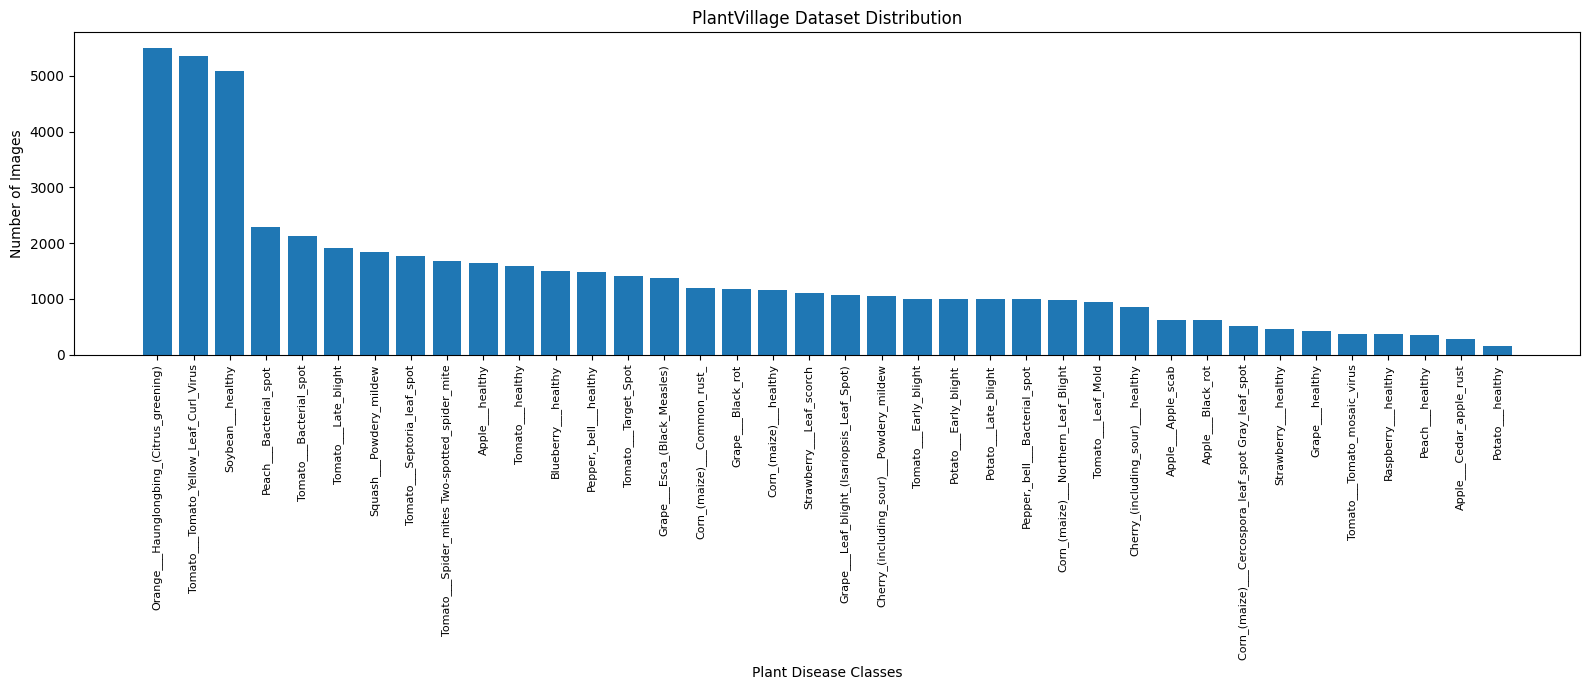

In [9]:

df_sorted = df.sort_values("Images", ascending=False)

plt.figure(figsize=(16, 7))

plt.bar(df_sorted["Class"], df_sorted["Images"])

plt.xticks(rotation=90, fontsize=8)
plt.xlabel("Plant Disease Classes")
plt.ylabel("Number of Images")
plt.title("PlantVillage Dataset Distribution")

plt.tight_layout()
plt.show()


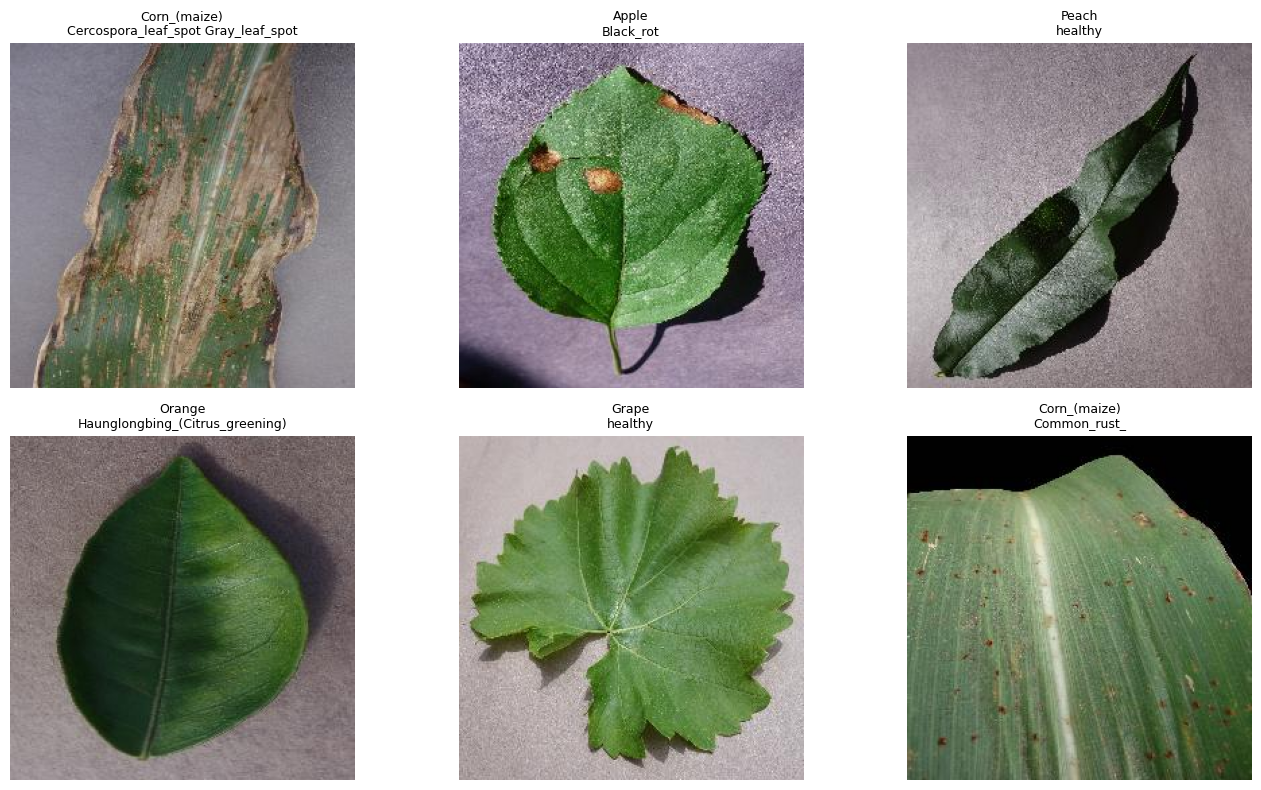

In [10]:

selected_classes = random.sample(
    classes, min(6, len(classes))
)

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, c in zip(axes.flat, selected_classes):

    folder = os.path.join(DATA_DIR, c)

    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    filename = random.choice(files)

    with Image.open(os.path.join(folder, filename)) as img:
        ax.imshow(img.convert("RGB"))

    ax.set_title(c.replace("___", "\n"), fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()


**Duplicate Detection**

In [12]:

size_groups = defaultdict(list)

for root, dirs, files in os.walk(DATA_DIR):
    for filename in files:

        if filename.lower().endswith(
            (".jpg", ".jpeg", ".png", ".bmp")
        ):
            path = os.path.join(root, filename)
            size_groups[os.path.getsize(path)].append(path)


def get_hash(path):
    sha = hashlib.sha256()

    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha.update(chunk)

    return sha.hexdigest()


hash_groups = defaultdict(list)

for paths in size_groups.values():
    if len(paths) > 1:

        for path in paths:
            hash_groups[get_hash(path)].append(path)


duplicates = {
    h: paths
    for h, paths in hash_groups.items()
    if len(paths) > 1
}

print("Exact duplicate groups:", len(duplicates))
print(
    "Extra duplicate files:",
    sum(len(paths) - 1 for paths in duplicates.values())
)


Exact duplicate groups: 21
Extra duplicate files: 21


In [13]:

for i, paths in enumerate(duplicates.values(), 1):

    print(f"\nDuplicate group {i}")

    for path in paths:
        print(os.path.relpath(path, DATA_DIR))



Duplicate group 1
Tomato___Late_blight/1a69b38b-c4eb-42c4-9584-bcb14fb8db0c___GHLB2 Leaf 9011.JPG
Tomato___Late_blight/2c47b891-3c97-48f1-a2cc-5aa53d3a1148___GHLB2 Leaf 9011.JPG

Duplicate group 2
Tomato___Late_blight/5de6da85-f8c4-48c4-b463-3e6bd78884cc___GHLB_PS Leaf 24 Day 16.jpg
Tomato___Late_blight/3fae9c64-18f0-4a67-9f97-554248bb1bed___GHLB_PS Leaf 24 Day 16.jpg

Duplicate group 3
Tomato___Late_blight/bd4f09bd-ee85-4ab1-bce0-8cde3fdd7f1b___GHLB_PS Leaf 23.7 Day 13.jpg
Tomato___Late_blight/48c55974-9fe9-4f4b-94f7-c8cd127d1e05___GHLB_PS Leaf 23.7 Day 13.jpg

Duplicate group 4
Tomato___Late_blight/c1775bad-7c02-41fb-bb7d-f8df91d60ac3___GHLB_PS Leaf 23.5 Day 13.jpg
Tomato___Late_blight/98586693-fe1f-4ea0-8e27-4501b61cf09b___GHLB_PS Leaf 23.5 Day 13.jpg

Duplicate group 5
Tomato___Late_blight/e20107e7-137f-400e-817f-5dc4c58e5d70___GHLB2 Leaf 8677.JPG
Tomato___Late_blight/5688ea99-c949-41d0-bbab-9cbf0ffb8bcd___GHLB2 Leaf 8677.JPG

Duplicate group 6
Tomato___Late_blight/d82b634e-9a19-4

In [14]:

duplicate_paths = set()

for paths in duplicates.values():
    duplicate_paths.update(paths[1:])

image_paths = []
image_labels = []

for c in classes:

    folder = os.path.join(DATA_DIR, c)

    for filename in sorted(os.listdir(folder)):

        if not filename.lower().endswith(
            (".jpg", ".jpeg", ".png")
        ):
            continue

        path = os.path.join(folder, filename)

        if path not in duplicate_paths:
            image_paths.append(path)
            image_labels.append(c)

print("Original images:", sum(class_counts.values()))
print("Images excluded as exact duplicates:", len(duplicate_paths))
print("Remaining unique images:", len(image_paths))


Original images: 54305
Images excluded as exact duplicates: 21
Remaining unique images: 54284


In [15]:

crop_summary = {}

for crop in sorted(set(c.split("___")[0] for c in classes)):

    crop_classes = [
        c for c in classes
        if c.startswith(crop + "___")
    ]

    crop_summary[crop] = {
        c: class_counts[c]
        for c in crop_classes
    }

for crop, counts in crop_summary.items():

    print("\n", crop)
    print("Classes:", len(counts))
    print("Images:", sum(counts.values()))

    for c, n in counts.items():
        print(" ", c, ":", n)



 Apple
Classes: 4
Images: 3171
  Apple___Apple_scab : 630
  Apple___Black_rot : 621
  Apple___Cedar_apple_rust : 275
  Apple___healthy : 1645

 Blueberry
Classes: 1
Images: 1502
  Blueberry___healthy : 1502

 Cherry_(including_sour)
Classes: 2
Images: 1906
  Cherry_(including_sour)___Powdery_mildew : 1052
  Cherry_(including_sour)___healthy : 854

 Corn_(maize)
Classes: 4
Images: 3852
  Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot : 513
  Corn_(maize)___Common_rust_ : 1192
  Corn_(maize)___Northern_Leaf_Blight : 985
  Corn_(maize)___healthy : 1162

 Grape
Classes: 4
Images: 4062
  Grape___Black_rot : 1180
  Grape___Esca_(Black_Measles) : 1383
  Grape___Leaf_blight_(Isariopsis_Leaf_Spot) : 1076
  Grape___healthy : 423

 Orange
Classes: 1
Images: 5507
  Orange___Haunglongbing_(Citrus_greening) : 5507

 Peach
Classes: 2
Images: 2657
  Peach___Bacterial_spot : 2297
  Peach___healthy : 360

 Pepper,_bell
Classes: 2
Images: 2475
  Pepper,_bell___Bacterial_spot : 997
  Pepper,_bell___h

In [10]:
import os

DATA_DIR = "/kaggle/working/PlantVillage-Dataset/raw/color"

print("Dataset path:", DATA_DIR)
print("Folder exists:", os.path.exists(DATA_DIR))

if os.path.exists(DATA_DIR):
    print("Number of class folders:",
          len([x for x in os.listdir(DATA_DIR)
               if os.path.isdir(os.path.join(DATA_DIR, x))]))
else:
    print("Dataset folder not found.")
    print("Current working directory:", os.getcwd())
    print("Working directory contents:", os.listdir("/kaggle/working"))

Dataset path: /kaggle/working/PlantVillage-Dataset/raw/color
Folder exists: True
Number of class folders: 38


In [12]:
import os

CLASSES = [
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy"
]

class_counts = {}

for c in CLASSES:
    folder = os.path.join(DATA_DIR, c)

    if os.path.exists(folder):
        images = [
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ]
        class_counts[c] = len(images)
    else:
        class_counts[c] = 0
        print("Missing folder:", c)

print("\nPOTATO DATASET SUMMARY")
for c, count in class_counts.items():
    print(f"{c}: {count}")

print("\nTotal Potato images:", sum(class_counts.values()))


POTATO DATASET SUMMARY
Potato___Early_blight: 1000
Potato___Late_blight: 1000
Potato___healthy: 152

Total Potato images: 2152


In [14]:
import os
import numpy as np
import hashlib

DATA_DIR = "/kaggle/working/PlantVillage-Dataset/raw/color"

CLASSES = [
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy"
]

selected_paths = []
selected_labels = []

seen_hashes = set()
duplicate_paths = set()

for label, class_name in enumerate(CLASSES):

    folder = os.path.join(DATA_DIR, class_name)

    if not os.path.isdir(folder):
        raise FileNotFoundError(f"Class folder not found: {folder}")

    for filename in sorted(os.listdir(folder)):

        if not filename.lower().endswith((".jpg", ".jpeg", ".png")):
            continue

        path = os.path.join(folder, filename)

        # Calculate image hash to identify exact duplicates
        with open(path, "rb") as file:
            image_hash = hashlib.sha256(file.read()).hexdigest()

        if image_hash in seen_hashes:
            duplicate_paths.add(path)
            continue

        seen_hashes.add(image_hash)

        selected_paths.append(path)
        selected_labels.append(label)

selected_paths = np.array(selected_paths)
selected_labels = np.array(selected_labels)

print("SELECTED DATASET SUMMARY")
print("------------------------")
print("Selected classes:", CLASSES)
print("Total images:", len(selected_paths))
print("Exact duplicates removed:", len(duplicate_paths))

for i, class_name in enumerate(CLASSES):
    print(class_name, np.sum(selected_labels == i))

SELECTED DATASET SUMMARY
------------------------
Selected classes: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
Total images: 2152
Exact duplicates removed: 0
Potato___Early_blight 1000
Potato___Late_blight 1000
Potato___healthy 152


In [16]:
SEED = 42

import random
import numpy as np
import tensorflow as tf

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed set to:", SEED)

Random seed set to: 42


In [17]:

from sklearn.model_selection import train_test_split

p_train, p_temp, y_train, y_temp = train_test_split(
    selected_paths,
    selected_labels,
    test_size=0.30,
    random_state=SEED,
    stratify=selected_labels
)

p_val, p_test, y_val, y_test = train_test_split(
    p_temp,
    y_temp,
    test_size=0.50,
    random_state=SEED,
    stratify=y_temp
)

print("Training images:", len(p_train))
print("Validation images:", len(p_val))
print("Testing images:", len(p_test))


Training images: 1506
Validation images: 323
Testing images: 323


In [19]:
import pandas as pd

split_table = pd.DataFrame({
    "Class": CLASSES,
    "Train": [
        np.sum(y_train == i) for i in range(len(CLASSES))
    ],
    "Validation": [
        np.sum(y_val == i) for i in range(len(CLASSES))
    ],
    "Test": [
        np.sum(y_test == i) for i in range(len(CLASSES))
    ]
})

display(split_table)


,Class,Train,Validation,Test
0,Potato___Early_blight,700,150,150
1,Potato___Late_blight,700,150,150
2,Potato___healthy,106,23,23


In [20]:

from sklearn.utils.class_weight import compute_class_weight

class_weights_array = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(y_train),
    y=y_train
)

class_weights = dict(
    enumerate(class_weights_array)
)

print("Class weights:")

for i, weight in class_weights.items():
    print(CLASSES[i], round(weight, 3))


Class weights:
Potato___Early_blight 0.717
Potato___Late_blight 0.717
Potato___healthy 4.736


In [21]:

import tensorflow as tf

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = len(CLASSES)

def load_image(path, label):

    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        (IMG_SIZE, IMG_SIZE)
    )

    return image, label


def make_dataset(paths, labels, shuffle=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=SEED
        )

    return dataset.batch(BATCH_SIZE).prefetch(
        tf.data.AUTOTUNE
    )


train_ds = make_dataset(p_train, y_train, True)
val_ds = make_dataset(p_val, y_val)
test_ds = make_dataset(p_test, y_test)

print("Datasets prepared successfully.")


I0000 00:00:1795024120.536245     135 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1795024120.540003     135 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Datasets prepared successfully.


In [22]:

from tensorflow.keras import layers, models

from tensorflow.keras.applications import VGG16
from tensorflow.keras.applications.vgg16 import preprocess_input

print("Model libraries imported.")


Model libraries imported.


In [23]:

augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1)
])

print("Data augmentation prepared.")


Data augmentation prepared.


In [24]:

def build_cnn():

    model = models.Sequential([

        layers.Input(shape=(224, 224, 3)),

        layers.Rescaling(1./255),

        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(),

        layers.Conv2D(64, 3, activation="relu"),
        layers.MaxPooling2D(),

        layers.Conv2D(128, 3, activation="relu"),
        layers.MaxPooling2D(),

        layers.Flatten(),

        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),

        layers.Dense(NUM_CLASSES, activation="softmax")
    ])

    return model


cnn_model = build_cnn()

cnn_model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,347 (42.61 MB)

 Trainable params: 11,169,347 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [25]:

def build_vgg16(use_augmentation=False):

    base_model = VGG16(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )

    # Freeze pretrained convolutional layers
    base_model.trainable = False

    inputs = layers.Input(shape=(224, 224, 3))

    x = inputs

    if use_augmentation:
        x = augmentation(x)

    x = layers.Lambda(preprocess_input)(x)

    x = base_model(x, training=False)

    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dense(256, activation="relu")(x)

    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = models.Model(inputs, outputs)

    return model


vgg_model = build_vgg16(False)

vgg_model.summary()


58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,846,787 (56.64 MB)

 Trainable params: 132,099 (516.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [26]:

vgg_aug_model = build_vgg16(True)

vgg_aug_model.summary()


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │           771 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,846,787 (56.64 MB)

 Trainable params: 132,099 (516.01 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [29]:

def train_model(model, epochs):

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        class_weight=class_weights
    )

    return history


In [30]:

history_cnn = train_model(
    cnn_model,
    epochs=10
)


Epoch 1/10


2026-11-18 17:50:07.073715: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-18 17:50:07.221541: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


 3/48 ━━━━━━━━━━━━━━━━━━━━ 2s 52ms/step - accuracy: 0.4410 - loss: 1.8373

I0000 00:00:1795024209.968738     175 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


46/48 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step - accuracy: 0.4570 - loss: 1.3183

2026-11-18 17:50:13.159425: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-11-18 17:50:13.301427: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


48/48 ━━━━━━━━━━━━━━━━━━━━ 15s 151ms/step - accuracy: 0.5531 - loss: 0.9653 - val_accuracy: 0.8854 - val_loss: 0.3060
Epoch 2/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.8340 - loss: 0.3733 - val_accuracy: 0.7678 - val_loss: 0.4122
Epoch 3/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.9070 - loss: 0.2201 - val_accuracy: 0.7740 - val_loss: 0.6142
Epoch 4/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.8048 - loss: 0.4521 - val_accuracy: 0.8700 - val_loss: 0.2615
Epoch 5/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.9137 - loss: 0.1817 - val_accuracy: 0.8916 - val_loss: 0.2596
Epoch 6/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 54ms/step - accuracy: 0.9256 - loss: 0.1800 - val_accuracy: 0.8793 - val_loss: 0.3086
Epoch 7/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.9489 - loss: 0.1594 - val_accuracy: 0.9319 - val_loss: 0.1888
Epoch 8/10
48/48 ━━━━━━━━━━━━━━━━━━━━ 3s 53ms/step - accuracy: 0.9734 - loss: 0.0866 - val_accuracy: 0.8700 - val_loss: 

In [31]:

history_vgg = train_model(
    vgg_model,
    epochs=5
)


Epoch 1/5
48/48 ━━━━━━━━━━━━━━━━━━━━ 31s 328ms/step - accuracy: 0.7676 - loss: 1.0028 - val_accuracy: 0.9009 - val_loss: 0.3465
Epoch 2/5
48/48 ━━━━━━━━━━━━━━━━━━━━ 10s 201ms/step - accuracy: 0.9090 - loss: 0.2578 - val_accuracy: 0.9567 - val_loss: 0.1004
Epoch 3/5
48/48 ━━━━━━━━━━━━━━━━━━━━ 11s 206ms/step - accuracy: 0.9416 - loss: 0.1542 - val_accuracy: 0.9659 - val_loss: 0.1117
Epoch 4/5
48/48 ━━━━━━━━━━━━━━━━━━━━ 11s 214ms/step - accuracy: 0.9575 - loss: 0.1066 - val_accuracy: 0.9443 - val_loss: 0.1465
Epoch 5/5
48/48 ━━━━━━━━━━━━━━━━━━━━ 11s 219ms/step - accuracy: 0.9714 - loss: 0.0784 - val_accuracy: 0.9690 - val_loss: 0.0757


In [32]:

history_vgg_aug = train_model(
    vgg_aug_model,
    epochs=5
)


Epoch 1/5
48/48 ━━━━━━━━━━━━━━━━━━━━ 19s 214ms/step - accuracy: 0.7616 - loss: 0.8871 - val_accuracy: 0.9226 - val_loss: 0.2076
Epoch 2/5
48/48 ━━━━━━━━━━━━━━━━━━━━ 10s 187ms/step - accuracy: 0.9057 - loss: 0.3341 - val_accuracy: 0.9040 - val_loss: 0.2767
Epoch 3/5
48/48 ━━━━━━━━━━━━━━━━━━━━ 9s 182ms/step - accuracy: 0.9296 - loss: 0.2335 - val_accuracy: 0.9319 - val_loss: 0.1940
Epoch 4/5
48/48 ━━━━━━━━━━━━━━━━━━━━ 9s 176ms/step - accuracy: 0.9356 - loss: 0.1638 - val_accuracy: 0.9628 - val_loss: 0.0906
Epoch 5/5
48/48 ━━━━━━━━━━━━━━━━━━━━ 9s 172ms/step - accuracy: 0.9343 - loss: 0.1822 - val_accuracy: 0.9598 - val_loss: 0.1024


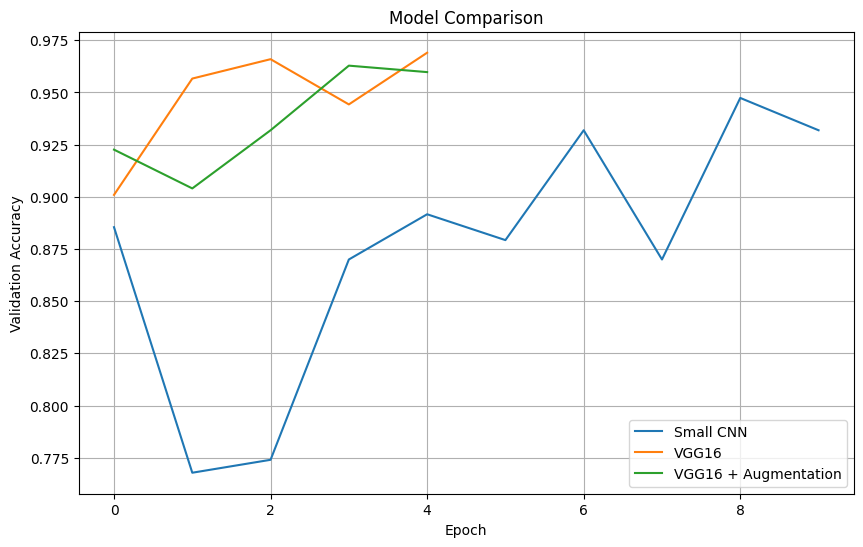

In [34]:
import matplotlib.pyplot as plt
histories = {
    "Small CNN": history_cnn,
    "VGG16": history_vgg,
    "VGG16 + Augmentation": history_vgg_aug
}

plt.figure(figsize=(10, 6))

for name, history in histories.items():

    plt.plot(
        history.history["val_accuracy"],
        label=name
    )

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy")
plt.title("Model Comparison")
plt.legend()
plt.grid()
plt.show()


In [35]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)


In [36]:

models_to_evaluate = {
    "Small CNN": cnn_model,
    "VGG16": vgg_model,
    "VGG16 + Augmentation": vgg_aug_model
}

results = []
predictions = {}

for name, model in models_to_evaluate.items():

    y_prob = model.predict(test_ds)
    y_pred = np.argmax(y_prob, axis=1)

    predictions[name] = y_pred

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    results.append([
        name, accuracy, precision, recall, f1
    ])

    print("\n", name)

    print(classification_report(
        y_test,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=CLASSES,
        zero_division=0
    ))

results_df = pd.DataFrame(
    results,
    columns=[
        "Model",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ]
)

display(results_df.round(4))

results_df.to_csv(
    "/kaggle/working/model_results.csv",
    index=False
)


11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 49ms/step

 Small CNN
                       precision    recall  f1-score   support

Potato___Early_blight       0.88      0.97      0.92       150
 Potato___Late_blight       0.93      0.85      0.89       150
     Potato___healthy       0.86      0.78      0.82        23

             accuracy                           0.90       323
            macro avg       0.89      0.87      0.88       323
         weighted avg       0.90      0.90      0.90       323

11/11 ━━━━━━━━━━━━━━━━━━━━ 3s 207ms/step

 VGG16
                       precision    recall  f1-score   support

Potato___Early_blight       0.99      0.99      0.99       150
 Potato___Late_blight       0.99      0.97      0.98       150
     Potato___healthy       0.85      0.96      0.90        23

             accuracy                           0.98       323
            macro avg       0.94      0.97      0.96       323
         weighted avg       0.98      0.98      0.98       323

11/11 ━━━━━

,Model,Accuracy,Precision,Recall,F1 Score
0,Small CNN,0.9009,0.8896,0.8675,0.8769
1,VGG16,0.9814,0.9442,0.9744,0.9582
2,VGG16 + Augmentation,0.9783,0.9338,0.9722,0.9511


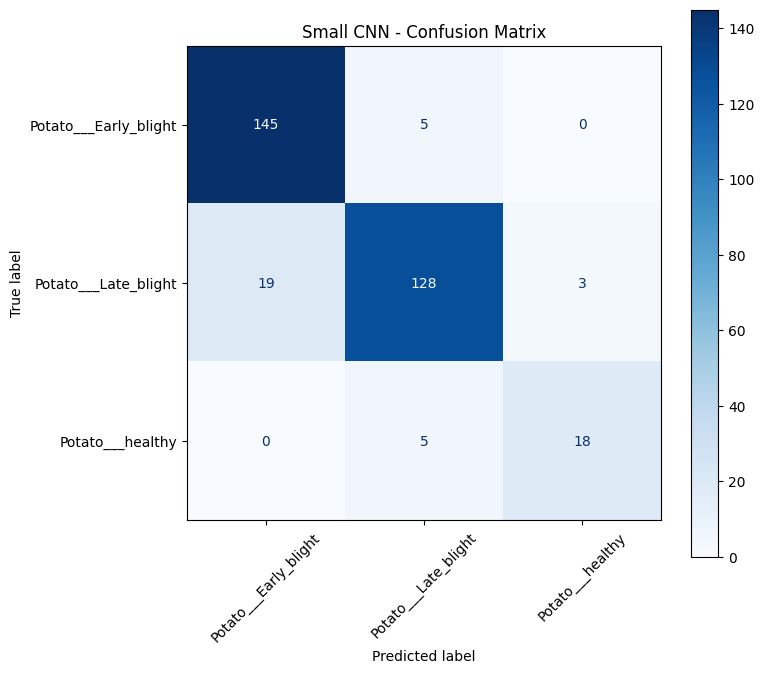

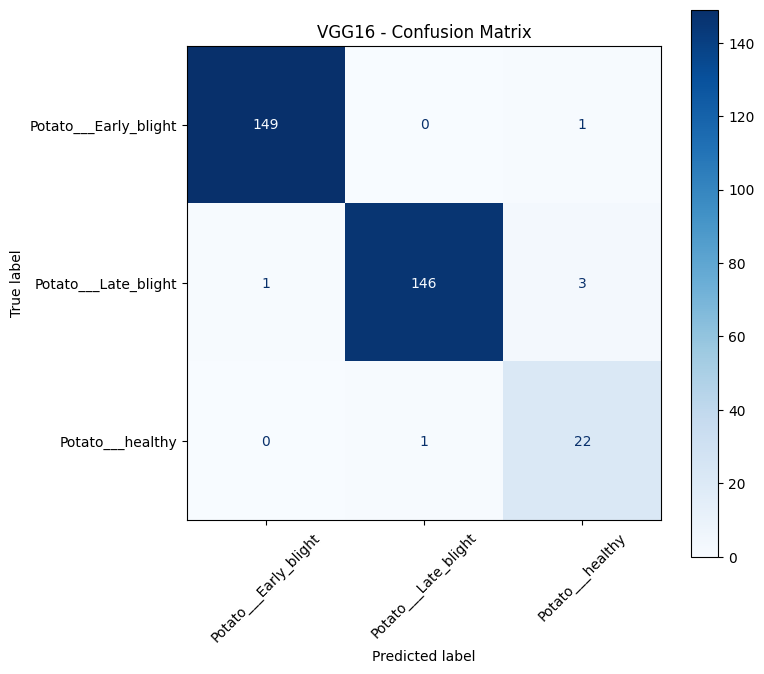

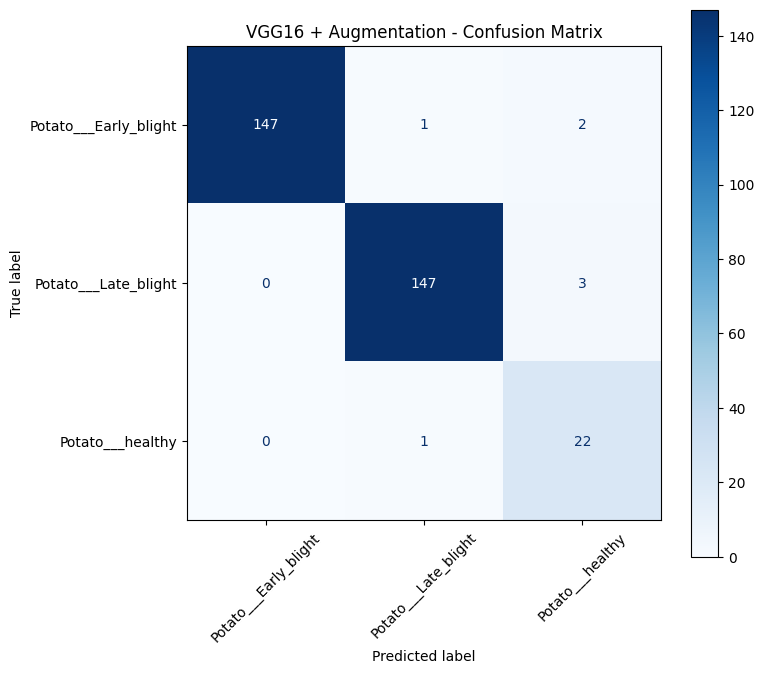

In [37]:

for name, y_pred in predictions.items():

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(NUM_CLASSES)
    )

    fig, ax = plt.subplots(figsize=(8, 7))

    display_cm = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=CLASSES
    )

    display_cm.plot(
        ax=ax,
        xticks_rotation=45,
        cmap="Blues",
        values_format="d"
    )

    plt.title(name + " - Confusion Matrix")
    plt.tight_layout()

    filename = (
        name.replace(" ", "_").replace("+", "plus")
        + "_confusion_matrix.png"
    )

    plt.savefig(
        "/kaggle/working/" + filename,
        bbox_inches="tight"
    )

    plt.show()


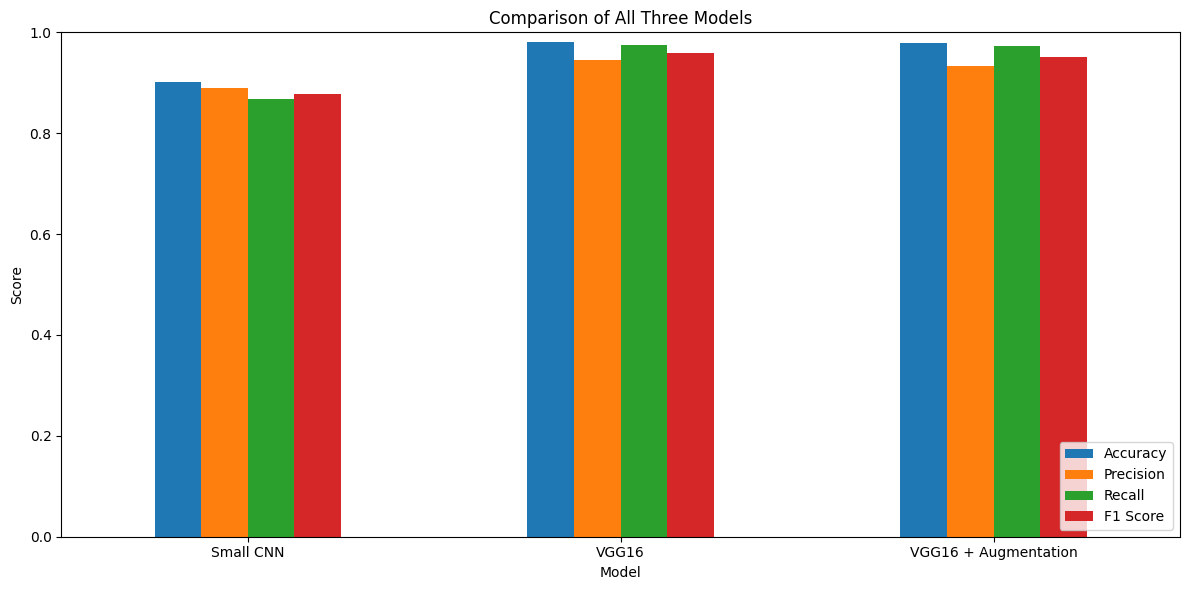

In [38]:

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

results_df.set_index("Model")[metrics].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Comparison of All Three Models")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


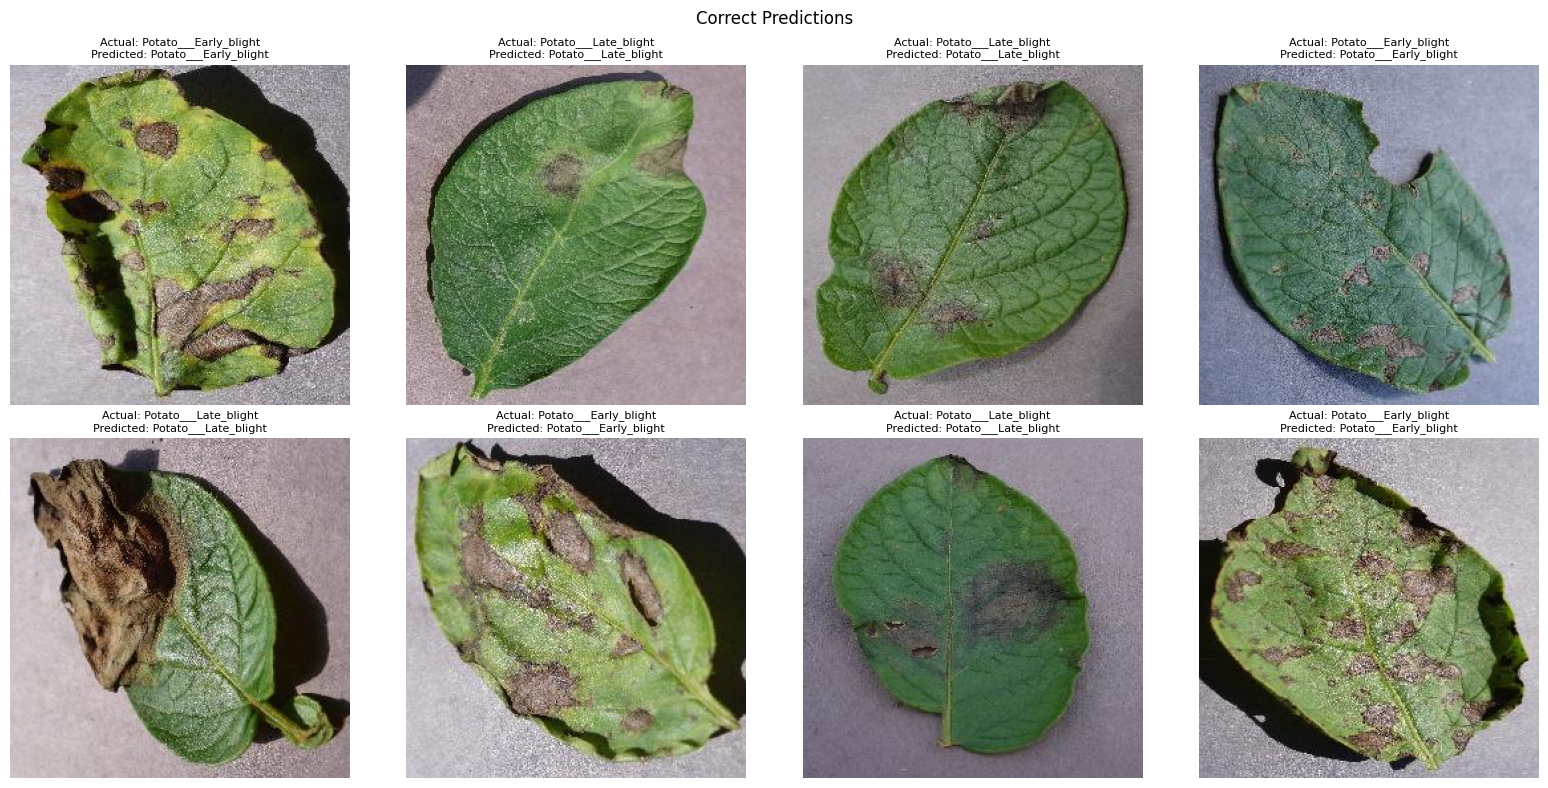

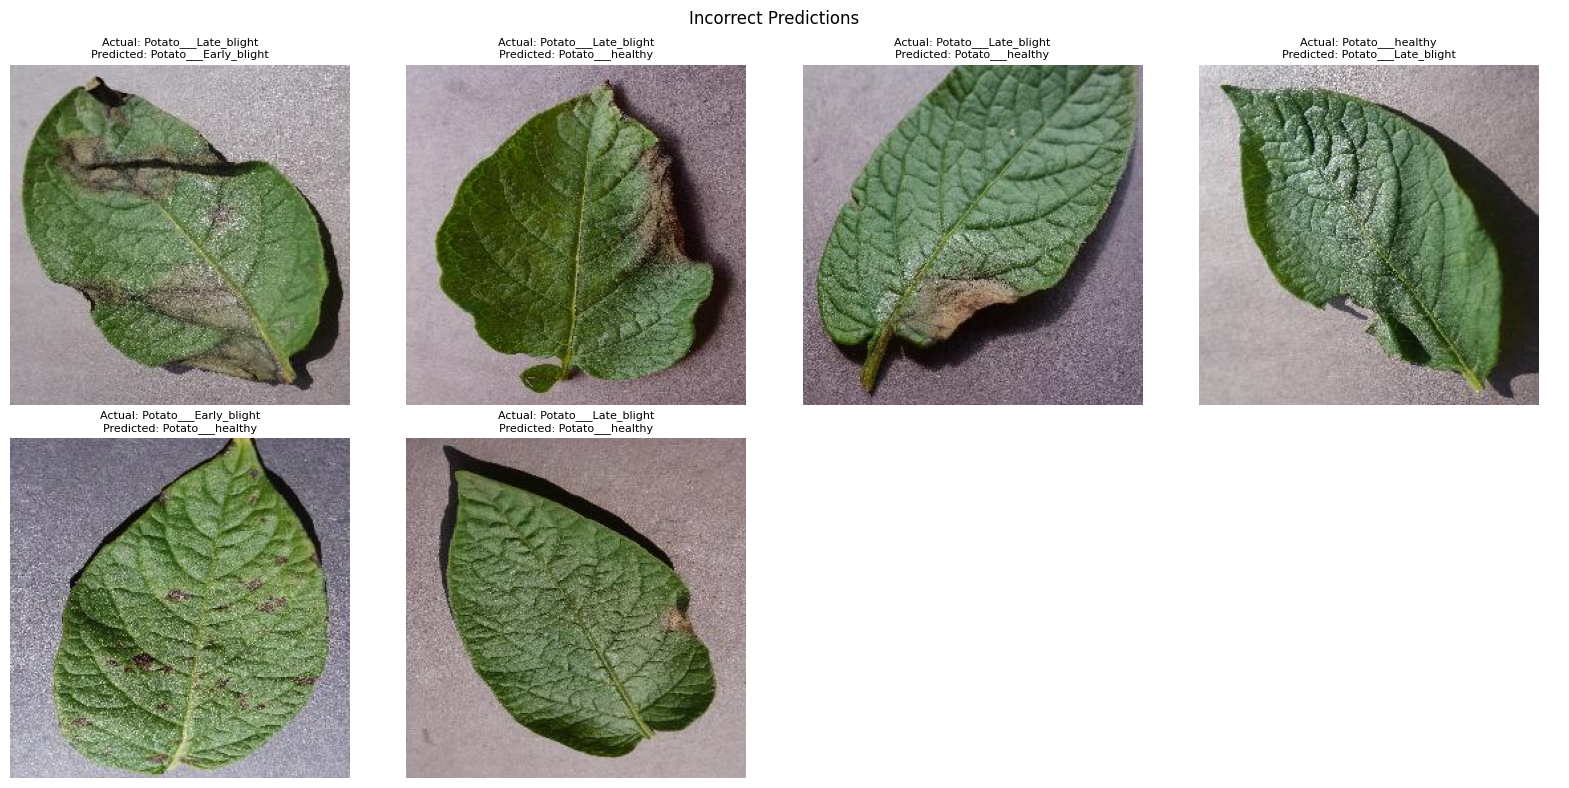

In [40]:

from PIL import Image

# Select VGG16 predictions for analysis
y_pred = predictions["VGG16"]

correct = np.where(y_pred == y_test)[0]
incorrect = np.where(y_pred != y_test)[0]


def display_predictions(indices, title):

    indices = indices[:8]

    if len(indices) == 0:
        print("No images available for:", title)
        return

    fig, axes = plt.subplots(
        2, 4, figsize=(16, 8)
    )

    for ax, idx in zip(axes.flat, indices):

        with Image.open(p_test[idx]) as img:
            ax.imshow(img.convert("RGB"))

        actual = CLASSES[y_test[idx]]
        predicted = CLASSES[y_pred[idx]]

        ax.set_title(
            f"Actual: {actual}\nPredicted: {predicted}",
            fontsize=8
        )

        ax.axis("off")

    for ax in axes.flat[len(indices):]:
        ax.axis("off")

    plt.suptitle(title)
    plt.tight_layout()
    plt.show()


display_predictions(correct, "Correct Predictions")
display_predictions(incorrect, "Incorrect Predictions")


In [41]:

cnn_model.save("/kaggle/working/small_cnn.keras")

vgg_model.save("/kaggle/working/vgg16.keras")

vgg_aug_model.save("/kaggle/working/vgg16_augmentation.keras")

print("All three models saved successfully.")


All three models saved successfully.
